# Week4_ex3 — Wind plant models: fixed power factor with a capacitor (type 1/2) against voltage control (type 3/4)

Reproduces Problem 6.61 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.), with the cases Problem6_61_PQ and Problem6_61_PV: the same seven-bus system with a 100 MW wind plant at bus 4, compared before and after line 2-4 opens, then pushed beyond the problem with output and reactive-load sweeps.

![PowerWorld one-line](Images/Week4_ex3_result_image.png)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# 1. Case data, PowerWorld results and the solver are in case7.py next to this notebook
from case7 import (BUSES, CAP_MVAR, WIND_BUS, WIND_QLIM, build_case, compare, measure, residual_band, solve_pw,
                   state_rows, summarize, wind_q)

IMG = Path("Images")
IMG.mkdir(exist_ok=True)

In [2]:
# 2. Both plant models, intact and with line 2-4 open, against the saved PowerWorld solutions.
#    After the outage PowerWorld's area interchange control redispatched the units, so its dispatch is used
states = [("PQ", "pq", None), ("PV", "pv", None), ("PQ", "pq_out24", "2-4-1"), ("PV", "pv_out24", "2-4-1")]
solved, rows = {}, []
for model, key, outage in states:
    build = lambda m=model, k=key, o=outage: build_case(m, o, k)
    solved[key] = solve_pw(build())
    rows += state_rows(solved[key], key, residual_band(build, measure), f"Problem6_61 {key}")
check = compare(rows)
summarize(check)

,Group,Source,Rows,Max abs diff,Smallest margin,All pass
0,Bus voltage,Problem6_61 pq,7,2.097239e-06,8.000000e-08,True
1,Bus angle,Problem6_61 pq,7,8.980426e-03,2.000000e-06,True
2,Wind plant,Problem6_61 pq,1,4.837853e-07,4.516215e-06,True
3,Bus voltage,Problem6_61 pv,7,4.000000e-08,8.000000e-08,True
4,Bus angle,Problem6_61 pv,7,1.893013e-06,2.000000e-06,True
5,Wind plant,Problem6_61 pv,1,7.333082e-05,1.674735e-01,True
6,Bus voltage,Problem6_61 pq_out24,7,3.274329e-06,8.000000e-08,True
7,Bus angle,Problem6_61 pq_out24,7,8.873034e-03,2.000000e-06,True
8,Wind plant,Problem6_61 pq_out24,1,4.837853e-07,4.516215e-06,True
9,Bus voltage,Problem6_61 pv_out24,7,1.674967e-06,8.000000e-08,True


In [3]:
# 3. Problem 6.61: what happens at bus 4 when line 2-4 opens, and how the capacitor responds
def bus4(key):
    n = solved[key]
    return n.res_bus.vm_pu[WIND_BUS], wind_q(n), (-n.res_shunt.q_mvar.sum() if len(n.shunt) else 0.0)


rows = []
for model, before, after in (("Type 1/2 (PQ + capacitor)", "pq", "pq_out24"), ("Type 3/4 (PV)", "pv", "pv_out24")):
    (v0, q0, c0), (v1, q1, c1) = bus4(before), bus4(after)
    rows.append({"Plant": model, "V4 intact [pu]": v0, "V4 line 2-4 open [pu]": v1, "Voltage change [%]": (v1 / v0 - 1) * 100,
                 "Wind Q intact [Mvar]": q0, "Wind Q open [Mvar]": q1, "Capacitor intact [Mvar]": c0, "Capacitor open [Mvar]": c1})
answer = pd.DataFrame(rows)

# a fixed capacitor is a constant impedance: Q = Q_nom * V^2, so a 2.7% voltage dip costs it 5.3% of its output
v1 = solved["pq_out24"].res_bus.vm_pu[WIND_BUS]
assert abs(answer.loc[0, "Capacitor open [Mvar]"] - CAP_MVAR * v1 ** 2) < 1e-6
answer.round(4)

,Plant,V4 intact [pu],V4 line 2-4 open [pu],Voltage change [%],Wind Q intact [Mvar],Wind Q open [Mvar],Capacitor intact [Mvar],Capacitor open [Mvar]
0,Type 1/2 (PQ + capacitor),0.9996,0.9726,-2.6948,-48.4322,-48.4322,65.9436,62.4374
1,Type 3/4 (PV),1.0000,1.0000,0.0000,18.1954,42.8059,0.0000,0.0000


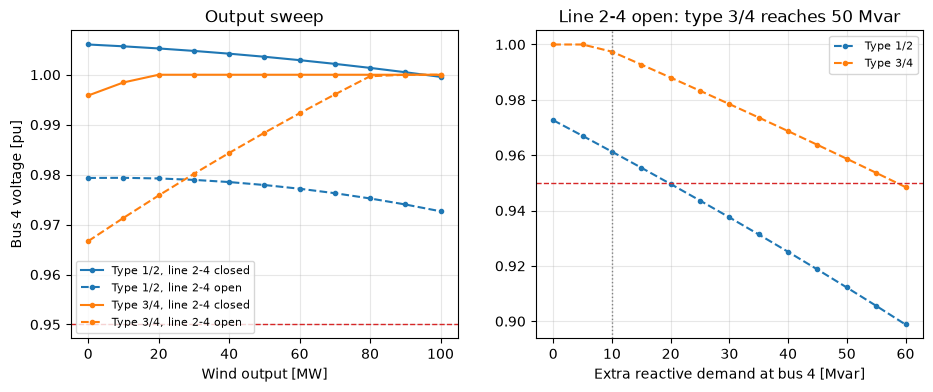

min     max  Range [pu]
Model Line 2-4                            
PQ    closed    0.9996  1.0061      0.0065
      open      0.9727  0.9794      0.0067
PV    closed    0.9958  1.0000      0.0042
      open      0.9667  1.0000      0.0333

,Model,Extra Mvar at bus 4,V4 [pu],Wind Q [Mvar],At limit
0,PQ,0,0.9726,-48.4322,False
1,PQ,5,0.9670,-48.4322,False
2,PQ,10,0.9613,-48.4322,False
12,PQ,60,0.8988,-48.4322,False
13,PV,0,1.0000,42.8059,False
14,PV,5,1.0000,47.8059,False
15,PV,10,0.9974,50.0000,True
25,PV,60,0.9485,50.0000,True


In [4]:
# 4. Beyond the problem: wind output from 0 to 100 MW with the line intact and open. The type 1/2 plant keeps
#    its 0.9 power factor, so it absorbs more Mvar as it produces more; the slack unit takes the MW change
rows = []
for model in ("PQ", "PV"):
    for outage in (None, "2-4-1"):
        for mw in range(0, 101, 10):
            net = build_case(model, outage)
            if model == "PQ":
                net.sgen.loc[net.sgen.name == "Wind", ["p_mw", "q_mvar"]] = [mw, -mw * (1 / 0.9 ** 2 - 1) ** 0.5]
            else:
                net.gen.loc[net.gen.name == "Wind", "p_mw"] = mw
            solve_pw(net)
            rows.append({"Model": model, "Line 2-4": "open" if outage else "closed", "Wind [MW]": mw,
                         "V4 [pu]": net.res_bus.vm_pu[WIND_BUS], "Wind Q [Mvar]": wind_q(net)})
output_sweep = pd.DataFrame(rows)

# below about 30 MW the type 1/2 plant does better with line 2-4 open: its 66 Mvar capacitor outweighs the
# type 3/4 plant's fixed +-50 Mvar range once the machine itself absorbs little

# 5. Reactive headroom: extra Mvar demand at bus 4 with line 2-4 open, until the type 3/4 plant runs out
rows = []
for model in ("PQ", "PV"):
    for extra in range(0, 61, 5):
        net = build_case(model, "2-4-1", "pq_out24" if model == "PQ" else "pv_out24")
        net.load.loc[net.load.bus == WIND_BUS, "q_mvar"] += extra
        solve_pw(net)
        rows.append({"Model": model, "Extra Mvar at bus 4": extra, "V4 [pu]": net.res_bus.vm_pu[WIND_BUS],
                     "Wind Q [Mvar]": wind_q(net), "At limit": bool(net.parked)})
headroom = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (model, line), g in output_sweep.groupby(["Model", "Line 2-4"]):
    axes[0].plot(g["Wind [MW]"], g["V4 [pu]"], marker="o", ms=3, ls="-" if line == "closed" else "--",
                 color="tab:blue" if model == "PQ" else "tab:orange",
                 label=f"{'Type 3/4' if model == 'PV' else 'Type 1/2'}, line 2-4 {line}")
axes[0].set_xlabel("Wind output [MW]")
axes[0].set_ylabel("Bus 4 voltage [pu]")
axes[0].set_title("Output sweep")
axes[0].legend(fontsize=8)
for model, g in headroom.groupby("Model"):
    axes[1].plot(g["Extra Mvar at bus 4"], g["V4 [pu]"], marker="o", ms=3, ls="--",
                 color="tab:blue" if model == "PQ" else "tab:orange", label="Type 3/4" if model == "PV" else "Type 1/2")
first = headroom[(headroom.Model == "PV") & headroom["At limit"]]["Extra Mvar at bus 4"].min()
axes[1].axvline(first, color="gray", ls=":", lw=1)
axes[1].set_xlabel("Extra reactive demand at bus 4 [Mvar]")
axes[1].set_title(f"Line 2-4 open: type 3/4 reaches {WIND_QLIM:.0f} Mvar")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.axhline(0.95, color="tab:red", lw=1, ls="--")
    ax.grid(alpha=0.3)
fig.savefig(IMG / "Week4_ex3_wind_model_voltage_sweeps.png", dpi=150, bbox_inches="tight")
plt.show()

spread = output_sweep.groupby(["Model", "Line 2-4"])["V4 [pu]"].agg(["min", "max"])
spread["Range [pu]"] = spread["max"] - spread["min"]
display(spread.round(4))
headroom[headroom["Extra Mvar at bus 4"].isin([0, first - 5, first, 60])].round(4)